# **Monkeypox Skin Lesion Prediction**
---

- Task : Classification
- Objective : Memprediksi apakah suatu gambar kulit termasuk lesi cacar monyet atau bukan berdasarkan citra kulit
- Link Dataset : https://www.kaggle.com/datasets/joydippaul/mpox-skin-lesion-dataset-version-20-msld-v20/data

Penularan kasus MonkeyPox mengalami kenaikan yang sangat signifikan di beberapa negara Afrika, Eropa, Amerika, hingga Asia. Penularan kasus MonkeyPox juga dikhawatirkan akan menjadi kasus pandemik yang meluas pada semua negara seperti kasus Covid19 pada tahun 2020. Untuk mencegah penularan, penular (carrier) harus dapat diidentifikasi sejak awal sebelum menularkan kepada orang lain di dekatnya. Dengan memanfaatkan penginderaan jarak jauh seperti kamera berkualitas tinggi untuk melihat adanya ciri-ciri carrier pada masyarakat dapat memberikan peringatan dini untuk orang disekitarnya. Tetapi,
diperlukan ahli yang dapat menentukan apakah ciri-ciri pada kulit dapat dikategorikan sebagai MonkeyPox ataupun tidak. Dengan keterbatasan ahli untuk terus menerus melihat dan menilai ciri-ciri kulit menjadikan penentuan carrier lebih sulit dilakukan. Diperlukan sebuah sistem yang dapat mengklasifikasikan ciri-ciri kulit yang sehat, MonkeyPox ataupun penyakit lain dengan efisien, presisi, dan akurasi yang baik.

![](https://www.mdpi.com/diagnostics/diagnostics-15-00374/article_deploy/html/images/diagnostics-15-00374-g001.png)

In [1]:
# read, resize, plotting, splitting, encoding
import cv2
import os
import joblib
import numpy as np
import pandas as pd
import kagglehub
import matplotlib.pyplot as plt
import seaborn as sns
import time
from pathlib import Path
from PIL import Image

# modelling
import tensorflow as tf
from keras.layers import Conv2D, BatchNormalization, Dropout, Flatten
from keras.models import Sequential, load_model, Model
from tensorflow.keras.optimizers import Adam

import torch
import torch.nn as nn
import torchvision.models as models
from torch.nn import functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torchvision.transforms import ToTensor
from dataclasses import dataclass

# evaluation
from sklearn.metrics import confusion_matrix, classification_report

import warnings
warnings.filterwarnings('ignore')

In [2]:
!pip install -q luwiji

In [3]:
from luwiji.cnn import illustration

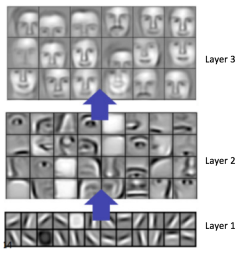

In [4]:
illustration.combination

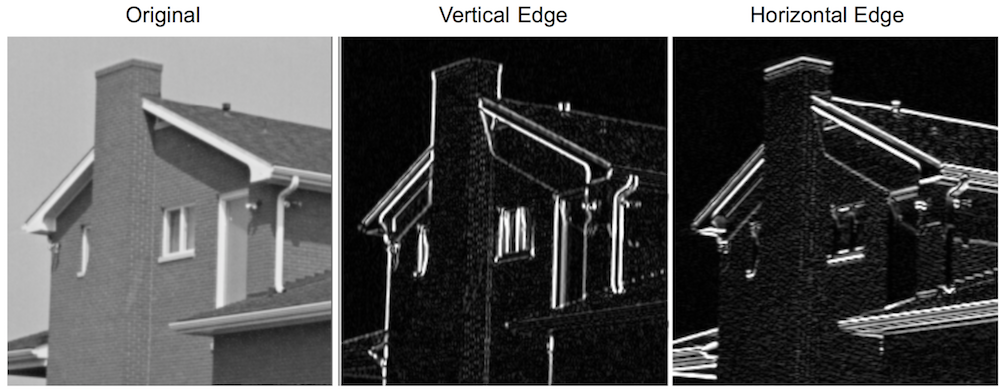

In [5]:
illustration.goal

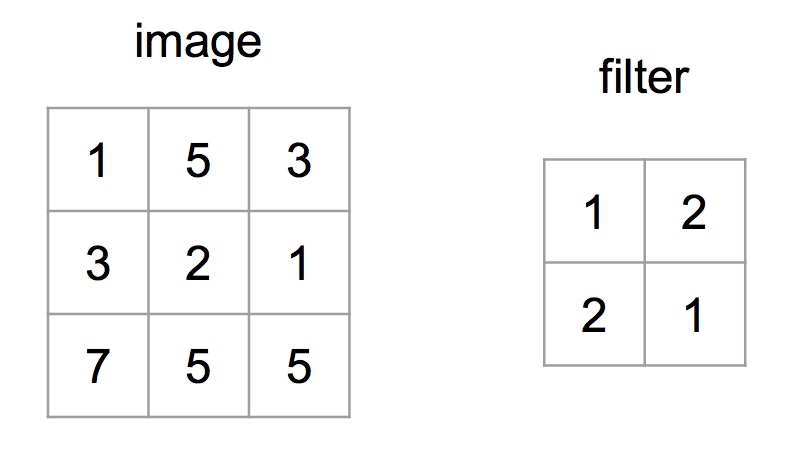

In [6]:
illustration.conv_ex1

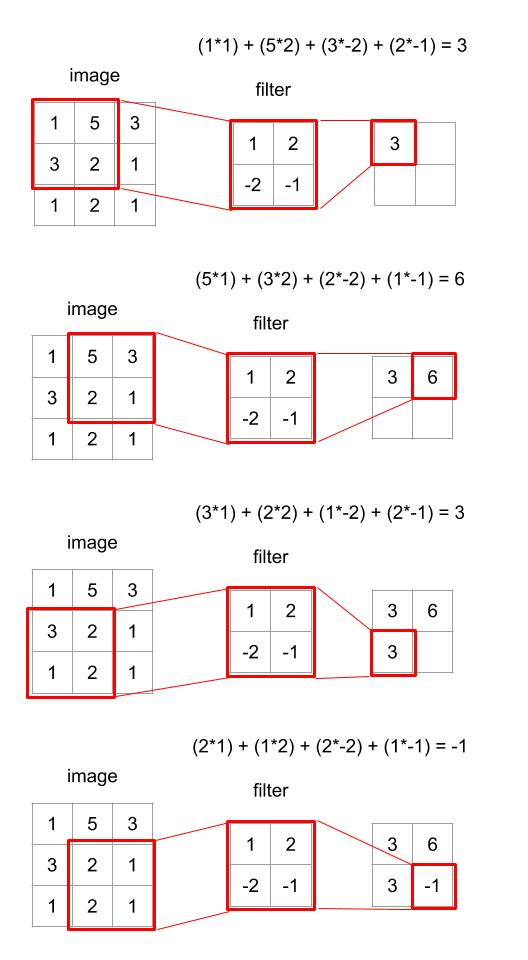

In [7]:
illustration.conv_ex2

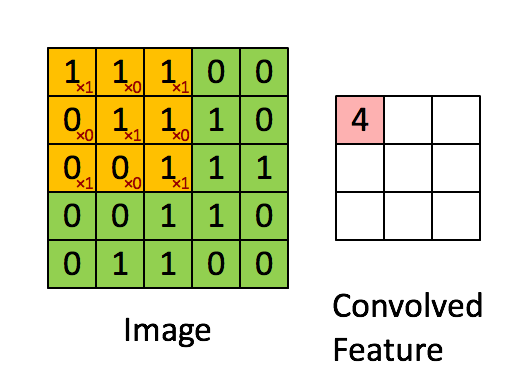

In [8]:
illustration.conv_ex3

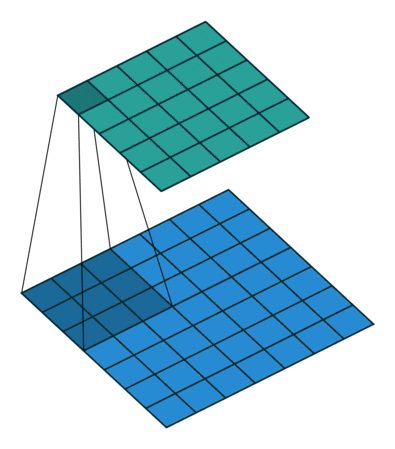

In [9]:
illustration.conv_ex4

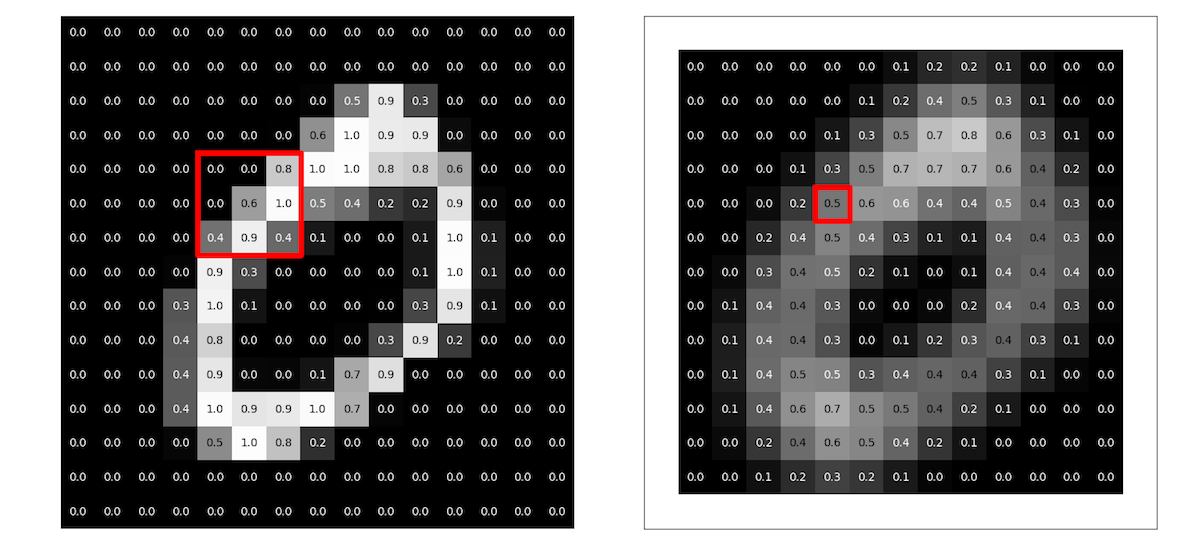

In [10]:
illustration.blur_avg

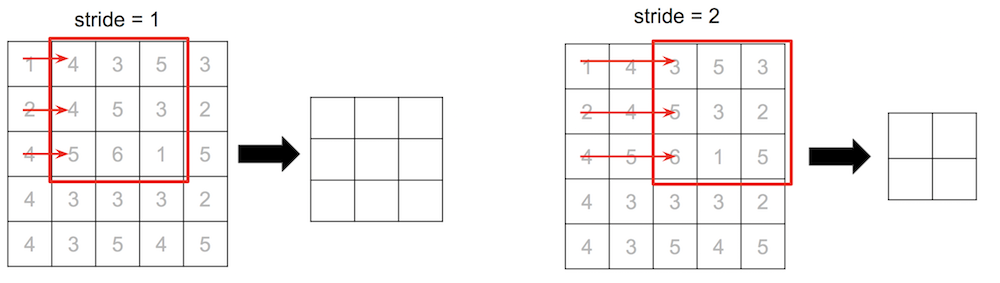

In [11]:
illustration.stride

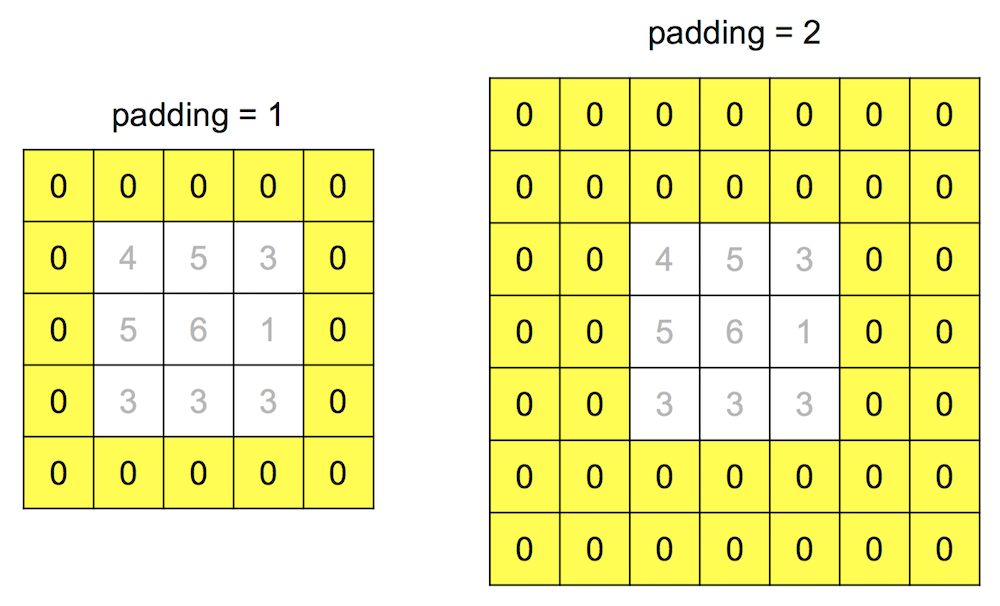

In [12]:
illustration.padding

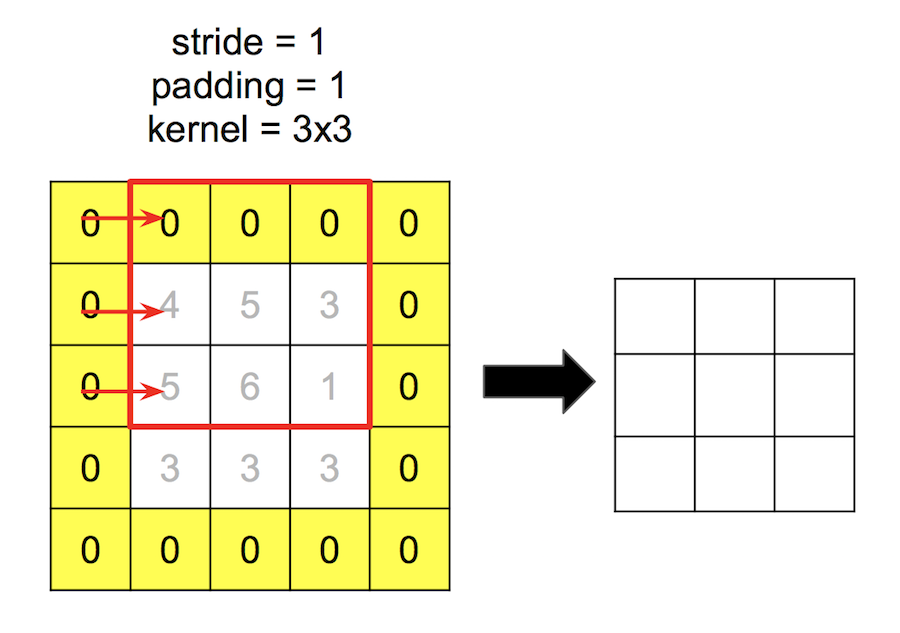

In [13]:
illustration.padding_same

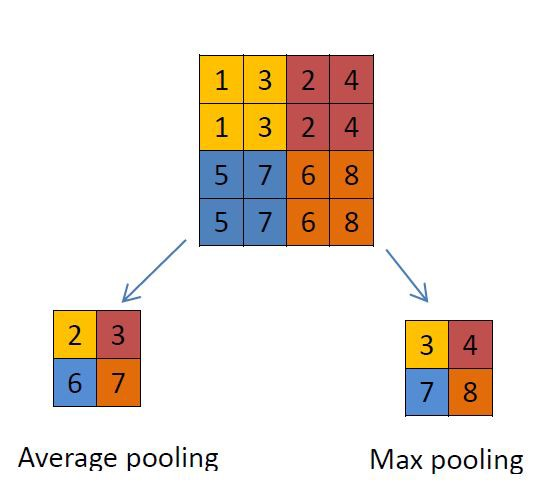

In [14]:
illustration.pooling

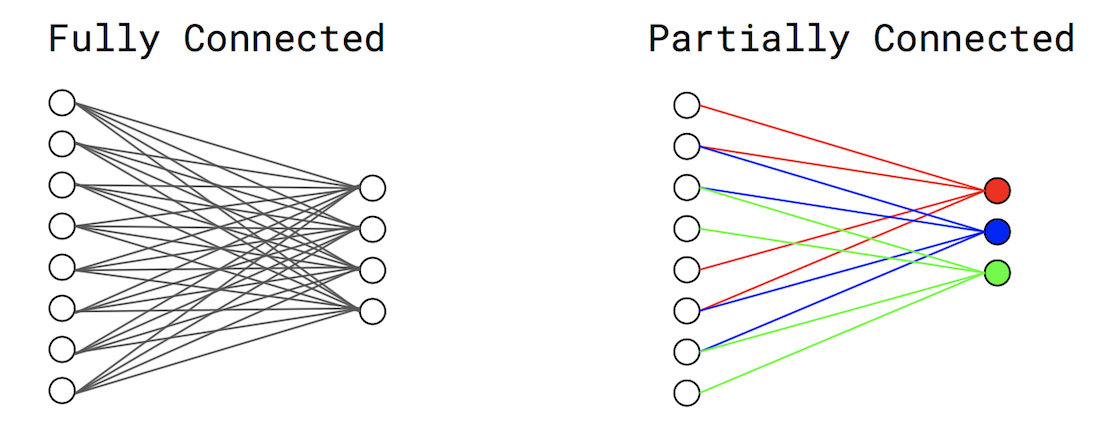

In [15]:
illustration.partial_con

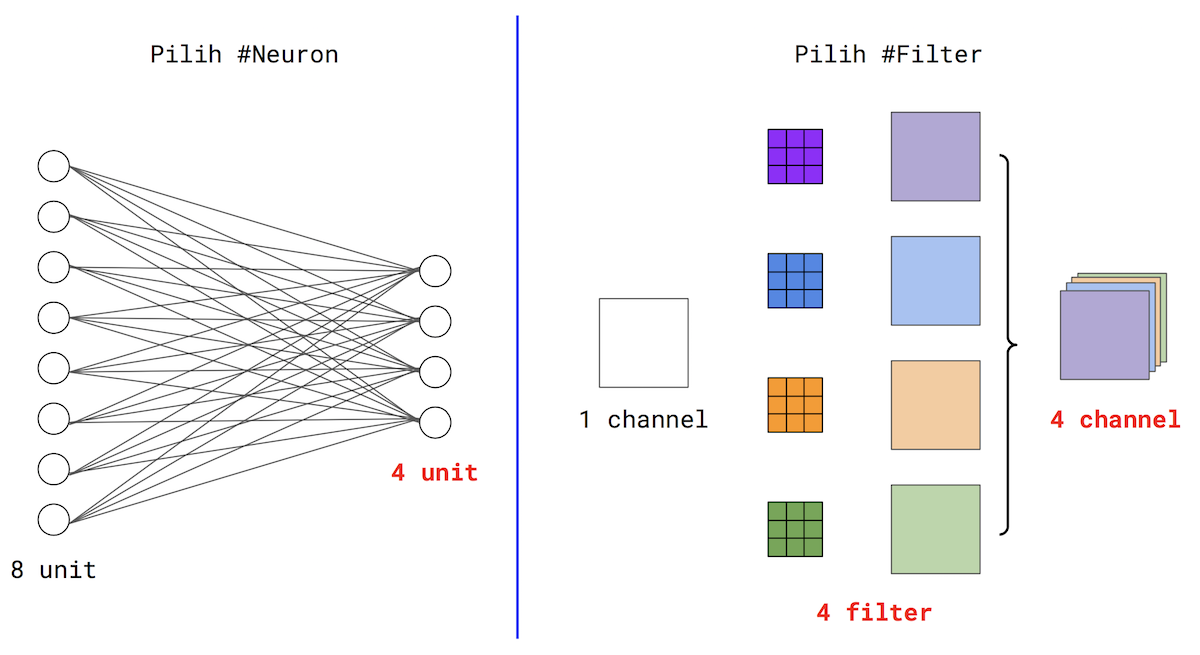

In [16]:
illustration.nn_vs_cnn

In [17]:
path = kagglehub.dataset_download("joydippaul/mpox-skin-lesion-dataset-version-20-msld-v20")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'mpox-skin-lesion-dataset-version-20-msld-v20' dataset.
Path to dataset files: /kaggle/input/mpox-skin-lesion-dataset-version-20-msld-v20


In [18]:
base_dir = '/root/.cache/kagglehub/datasets/joydippaul/mpox-skin-lesion-dataset-version-20-msld-v20/versions/4'
original_dir = os.path.join(base_dir, 'Original Images')

In [19]:
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

In [20]:
def load_data():
    base_dir = os.path.join(path, "Original Images", "Original Images", "FOLDS", "fold1")
    train_dataset = datasets.ImageFolder(os.path.join(base_dir, "Train"), transform=transform)
    valid_dataset = datasets.ImageFolder(os.path.join(base_dir, "Valid"), transform=transform)
    test_dataset = datasets.ImageFolder(os.path.join(base_dir, "Test"), transform=transform)

    return train_dataset, valid_dataset, test_dataset

train_dataset, valid_dataset, test_dataset = load_data()
class_names = train_dataset.classes

print("Class Names:", class_names)
print("Training samples:", len(train_dataset))
print("Validation samples:", len(valid_dataset))
print("Testing samples:", len(test_dataset))

Class Names: ['Chickenpox', 'Cowpox', 'HFMD', 'Healthy', 'Measles', 'Monkeypox']
Training samples: 537
Validation samples: 144
Testing samples: 74


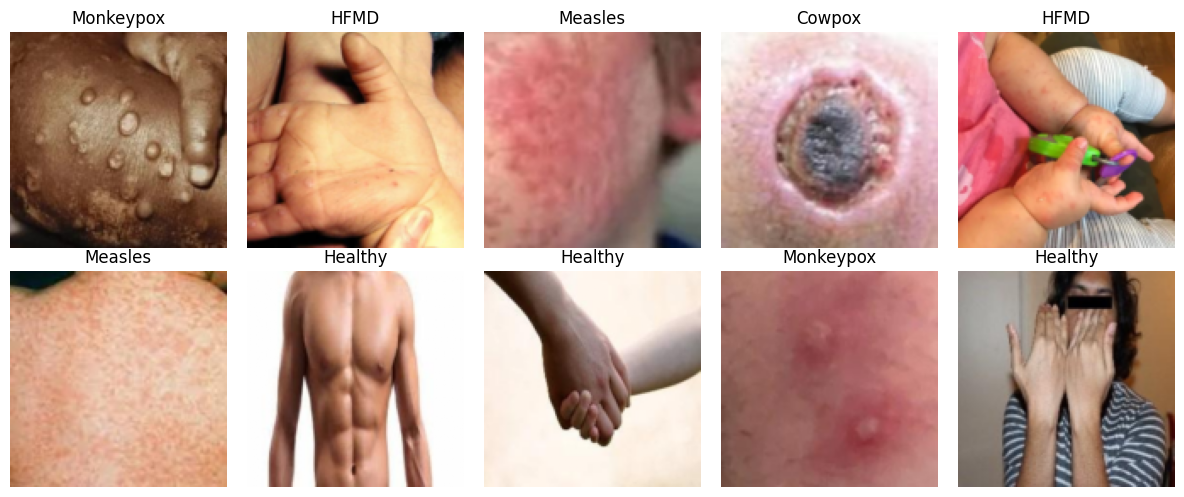

In [21]:
plt.figure(figsize=(12,5))
indices = np.random.randint(0, len(train_dataset), 10)

for i, idx in enumerate(indices):
    img, label = train_dataset[idx]
    img = img.numpy().transpose((1,2,0))

    plt.subplot(2,5,i+1)
    plt.imshow(img)
    plt.title(class_names[label])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [22]:
def check_dataset_info(base_dir):
    folders = ["Train", "Valid", "Test"]

    for folder in folders:
        folder_path = os.path.join(base_dir, folder)
        total_images = 0
        img_shape = None

        # Loop through class subfolders
        for class_name in os.listdir(folder_path):
            class_path = os.path.join(folder_path, class_name)

            if not os.path.isdir(class_path):
                continue

            for img_name in os.listdir(class_path):
                if img_name.lower().endswith((".jpg", ".jpeg", ".png")):
                    total_images += 1

                    # Get one sample image dimension
                    if img_shape is None:
                        img_path = os.path.join(class_path, img_name)

                        with Image.open(img_path) as img:
                            img_shape = img.size  # (W, H)

        print(f"{folder}")
        print(f"   Total gambar: {total_images}")
        print(f"   Ukuran contoh gambar (W,H): {img_shape}")
        print("-" * 40)

base_dir = os.path.join(path, "Original Images", "Original Images", "FOLDS", "fold1")
check_dataset_info(base_dir)

Train
   Total gambar: 537
   Ukuran contoh gambar (W,H): (195, 195)
----------------------------------------
Valid
   Total gambar: 144
   Ukuran contoh gambar (W,H): (145, 145)
----------------------------------------
Test
   Total gambar: 74
   Ukuran contoh gambar (W,H): (1216, 1216)
----------------------------------------


In [23]:
def count_class_distribution(dataset, dataset_name):
    class_names = dataset.classes
    labels = [label for _, label in dataset]
    df = pd.DataFrame({'labels': labels})
    df['class_name'] = df['labels'].apply(lambda x: class_names[x])

    print(f"\nDistribusi jumlah data per kelas ({dataset_name}):")
    print(df['class_name'].value_counts())

count_class_distribution(train_dataset, "Train")
count_class_distribution(valid_dataset, "Valid")
count_class_distribution(test_dataset, "Test")


Distribusi jumlah data per kelas (Train):
class_name
Monkeypox     202
HFMD          116
Healthy        83
Chickenpox     50
Cowpox         49
Measles        37
Name: count, dtype: int64

Distribusi jumlah data per kelas (Valid):
class_name
Monkeypox     55
HFMD          29
Healthy       22
Chickenpox    16
Measles       12
Cowpox        10
Name: count, dtype: int64

Distribusi jumlah data per kelas (Test):
class_name
Monkeypox     27
HFMD          16
Healthy        9
Chickenpox     9
Cowpox         7
Measles        6
Name: count, dtype: int64


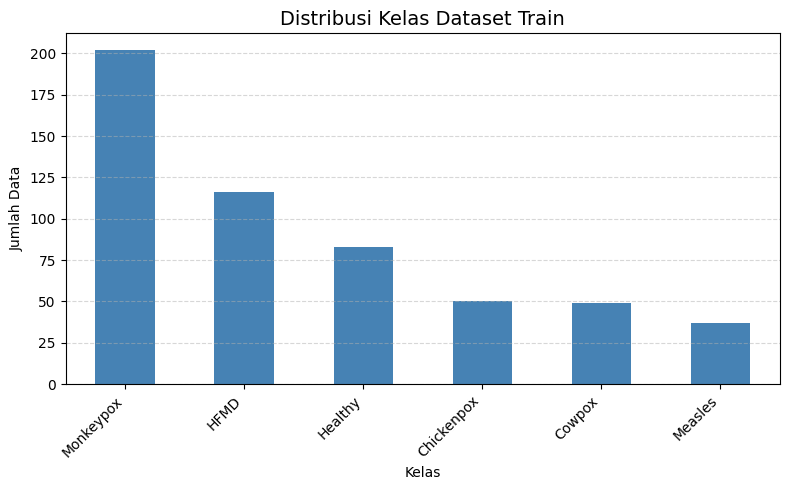

In [24]:
train_labels = train_dataset.targets
train_df = pd.DataFrame({'label_index': train_labels})
train_df['class_name'] = train_df['label_index'].apply(lambda x: class_names[x])
train_dist = train_df['class_name'].value_counts()
plt.figure(figsize=(8, 5))

# Urutkan dan plot
train_dist.sort_values(ascending=False).plot(kind='bar', color='steelblue')

plt.title('Distribusi Kelas Dataset Train', fontsize=14)
plt.xlabel('Kelas')
plt.ylabel('Jumlah Data')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# MLP

In [25]:
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=64, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=64, shuffle=False)

In [26]:
# Checking the dataset
for images, labels in train_loader:
    print('Image batch dimensions:', images.shape)
    print('Image label dimensions:', labels.shape)
    print('Class labels of 10 examples:', labels[:10])
    break

Image batch dimensions: torch.Size([64, 3, 128, 128])
Image label dimensions: torch.Size([64])
Class labels of 10 examples: tensor([5, 1, 4, 5, 0, 2, 2, 5, 0, 5])


In [27]:
for i, (imgs, targets) in enumerate(train_dataset):
    print(imgs.shape)

    if i > 2:
        break

torch.Size([3, 128, 128])
torch.Size([3, 128, 128])
torch.Size([3, 128, 128])
torch.Size([3, 128, 128])


In [28]:

@torch.no_grad()
def get_inference(model, type):
    """Get model accuracy and loss"""

    data_loader = {
        'train': train_loader,
        'valid': valid_loader,
        'test': test_loader
    }[type]

    device = next(model.parameters()).device

    correct_pred = 0
    num_samples = 0
    total_loss = 0.0

    model.eval()

    for imgs, targets in data_loader:

        # Move data to the same device as model
        imgs = imgs.to(device)
        targets = targets.to(device)

        # Prediction
        logits = model(imgs)
        probs = F.softmax(logits, dim=1)
        _, preds = torch.max(probs, 1)

        # Calculate accuracy and loss
        correct_pred += (preds == targets).sum().item()
        num_samples += targets.size(0)
        total_loss += F.cross_entropy(
            logits, targets, reduction='sum'
        ).item()

    acc = torch.tensor(
        100 * correct_pred / num_samples,
        device=device
    )

    loss = torch.tensor(
        total_loss / num_samples,
        device=device
    )

    return acc, loss

In [29]:
def train(model, max_epoch, train_loader, optimizer, criterion=None):

    train_acc_list = []
    valid_acc_list = []
    losses = []

    if criterion is None:
        criterion = nn.CrossEntropyLoss()

    device = next(model.parameters()).device

    # Ensure criterion weights are on the same device
    if hasattr(criterion, 'weight') and criterion.weight is not None:
        criterion.weight = criterion.weight.to(device)

    start_time = time.time()

    for epoch in range(max_epoch):
        model.train()

        for batch_idx, (imgs, targets) in enumerate(train_loader):

            # IMPORTANT: Move batch to GPU
            imgs = imgs.to(device)
            targets = targets.to(device)

            logits = model(imgs)
            loss = criterion(logits, targets)

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

            losses.append(loss.item())

            if batch_idx % max(1, len(train_loader) // 2) == 0:
                print(
                    f'Epoch: {epoch+1:03d}/{max_epoch:03d} '
                    f'| Batch: {batch_idx:04d}/{len(train_loader):04d} '
                    f'| Loss: {loss.item():.4f}'
                )

        model.eval()

        with torch.no_grad():
            train_acc, _ = get_inference(model, 'train')
            valid_acc, _ = get_inference(model, 'valid')

        print(
            f'Epoch: {epoch+1:03d}/{max_epoch:03d} '
            f'| Train: {train_acc.item():.2f}% '
            f'| Valid: {valid_acc.item():.2f}%'
        )

        train_acc_list.append(train_acc.item())
        valid_acc_list.append(valid_acc.item())

    elapsed = (time.time() - start_time) / 60
    print(f'Total Training Time: {elapsed:.2f} min')

    return losses, train_acc_list, valid_acc_list

## **MULTILAYER PERCEPTRON**
---

In [30]:
@dataclass
class ModelConfig:
    # Config model
    n_in: int = 3 * 128 * 128     # 12288
    n_hidden: int = 50
    n_out: int = 6
    drop_proba: float = 0.4

    # Config train
    lr: float = 1e-4
    max_epochs: int = 50
    batch_size: int = 64

In [31]:
CONFIG = ModelConfig()
CONFIG

ModelConfig(n_in=49152, n_hidden=50, n_out=6, drop_proba=0.4, lr=0.0001, max_epochs=50, batch_size=64)

In [32]:
class DeeperMLP(nn.Module):
    """
    MLP yang Lebih Dalam dengan Dua Lapisan Tersembunyi dan Dropout.
    """
    def __init__(self, config):
        super().__init__()

        # Inisialisasi agar dapat direproduksi
        torch.manual_seed(42)

        # Menggunakan node yang lebih banyak untuk lapisan tersembunyi
        self.n_hidden_1 = 4 * config.n_hidden  # 4 * 50 = 200 node
        self.n_hidden_2 = 2 * config.n_hidden  # 2 * 50 = 100 node

        self.model = nn.Sequential(
            # Flatten
            nn.Flatten(),

            # 1st hidden layer
            nn.Linear(config.n_in, self.n_hidden_1),
            nn.ReLU(),
            nn.Dropout(config.drop_proba),

            # 2nd hidden layer
            nn.Linear(self.n_hidden_1, self.n_hidden_2),
            nn.ReLU(),

            # 3rd hidden layer
            nn.Linear(self.n_hidden_2, config.n_out)
        )

    def forward(self, X):
        return self.model(X)

model_mlp_deeper = DeeperMLP(CONFIG)

print('Total parameters Deeper MLP:', sum(p.nelement() for p in model_mlp_deeper.parameters()))

Total parameters Deeper MLP: 9851306


In [33]:
# Initialize models
model_mlp = DeeperMLP(CONFIG)

# Print number of parameters
print('Total parameters :', sum(p.nelement() for p in model_mlp.parameters()))

Total parameters : 9851306


In [34]:
# Define optimizer
optimizer_1 = torch.optim.Adam(params=model_mlp.parameters(),
                               lr=CONFIG.lr)

In [35]:
losses_mlp, train_acc_mlp, valid_acc_mlp = train(model=model_mlp,
                                                 max_epoch=CONFIG.max_epochs,
                                                 train_loader=train_loader,
                                                 optimizer=optimizer_1)

Epoch: 001/050 | Batch: 0000/0009 | Loss: 1.7992
Epoch: 001/050 | Batch: 0004/0009 | Loss: 1.7761
Epoch: 001/050 | Batch: 0008/0009 | Loss: 1.7559
Epoch: 001/050 | Train: 37.62% | Valid: 38.19%
Epoch: 002/050 | Batch: 0000/0009 | Loss: 1.6421
Epoch: 002/050 | Batch: 0004/0009 | Loss: 1.7996
Epoch: 002/050 | Batch: 0008/0009 | Loss: 1.8035
Epoch: 002/050 | Train: 37.62% | Valid: 38.19%
Epoch: 003/050 | Batch: 0000/0009 | Loss: 1.6336
Epoch: 003/050 | Batch: 0004/0009 | Loss: 1.6795
Epoch: 003/050 | Batch: 0008/0009 | Loss: 1.6622
Epoch: 003/050 | Train: 38.18% | Valid: 38.19%
Epoch: 004/050 | Batch: 0000/0009 | Loss: 1.8266
Epoch: 004/050 | Batch: 0004/0009 | Loss: 1.6582
Epoch: 004/050 | Batch: 0008/0009 | Loss: 1.5457
Epoch: 004/050 | Train: 42.46% | Valid: 37.50%
Epoch: 005/050 | Batch: 0000/0009 | Loss: 1.5669
Epoch: 005/050 | Batch: 0004/0009 | Loss: 1.6646
Epoch: 005/050 | Batch: 0008/0009 | Loss: 2.0422
Epoch: 005/050 | Train: 40.60% | Valid: 38.19%
Epoch: 006/050 | Batch: 0000/0

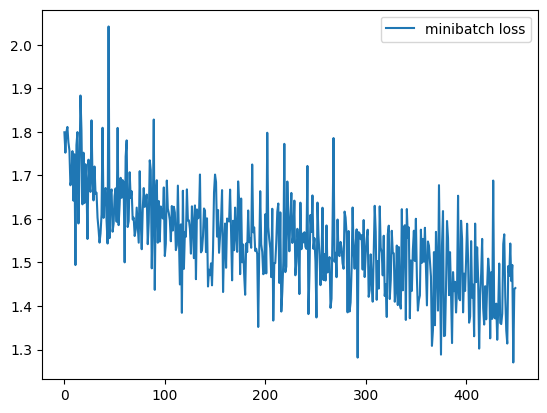

In [36]:
plt.plot(np.arange(len(losses_mlp)), losses_mlp, c='tab:blue', label='minibatch loss')
plt.legend()
plt.show()

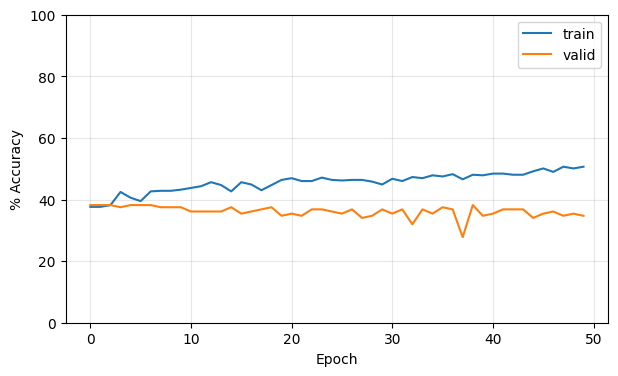

In [37]:
# simple plot (auto y-limits)
plt.figure(figsize=(7,4))
plt.plot(np.arange(len(train_acc_mlp)), train_acc_mlp, c='tab:blue', label='train')
plt.plot(np.arange(len(valid_acc_mlp)), valid_acc_mlp, c='tab:orange', label='valid')
plt.ylabel('% Accuracy')
plt.xlabel('Epoch')
plt.ylim(0, 100)     # akurasi dalam 0-100
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [38]:
# Calculate
train_acc_mlp, train_loss_mlp = get_inference(model_mlp, 'train')
valid_acc_mlp, valid_loss_mlp = get_inference(model_mlp, 'valid')
test_acc_mlp, test_loss_mlp = get_inference(model_mlp, 'test')

In [39]:
# Summarize in dataframe
summary_df = pd.DataFrame(
    np.array([[train_acc_mlp, valid_acc_mlp, test_acc_mlp, train_loss_mlp, valid_loss_mlp, test_loss_mlp]]),
    index = ['MLP'],
    columns = ['Train Acc', 'Valid Acc', 'Test Acc', 'Train Loss', 'Valid Loss', 'Test Loss']
)

summary_df

,Train Acc,Valid Acc,Test Acc,Train Loss,Valid Loss,Test Loss
MLP,50.651768,34.722221,39.18919,1.36447,1.633735,1.619581


In [40]:
# Mapping label sesuai ImageFolder
class_names = train_dataset.classes
labels_map = {i: name for i, name in enumerate(class_names)}
print(labels_map)

{0: 'Chickenpox', 1: 'Cowpox', 2: 'HFMD', 3: 'Healthy', 4: 'Measles', 5: 'Monkeypox'}


In [41]:
# Ambil batch dari validation set
X_samples, y_samples = next(iter(valid_loader))

In [42]:
# Get prediction
model_mlp.eval()
with torch.no_grad():
    logits_sample = model_mlp(X_samples)
    probs_sample = F.softmax(logits_sample, dim=1)
    y_samples_pred = probs_sample.max(1, keepdim=True)[1].view(-1)

y_samples_pred

tensor([5, 5, 5, 5, 5, 5, 5, 2, 5, 2, 3, 5, 5, 5, 5, 2, 2, 2, 5, 5, 5, 5, 5, 5,
        5, 5, 5, 2, 5, 5, 5, 5, 2, 2, 5, 2, 5, 5, 5, 2, 2, 2, 5, 5, 5, 2, 2, 5,
        5, 5, 5, 5, 2, 5, 5, 5, 5, 5, 2, 2, 5, 3, 2, 5])

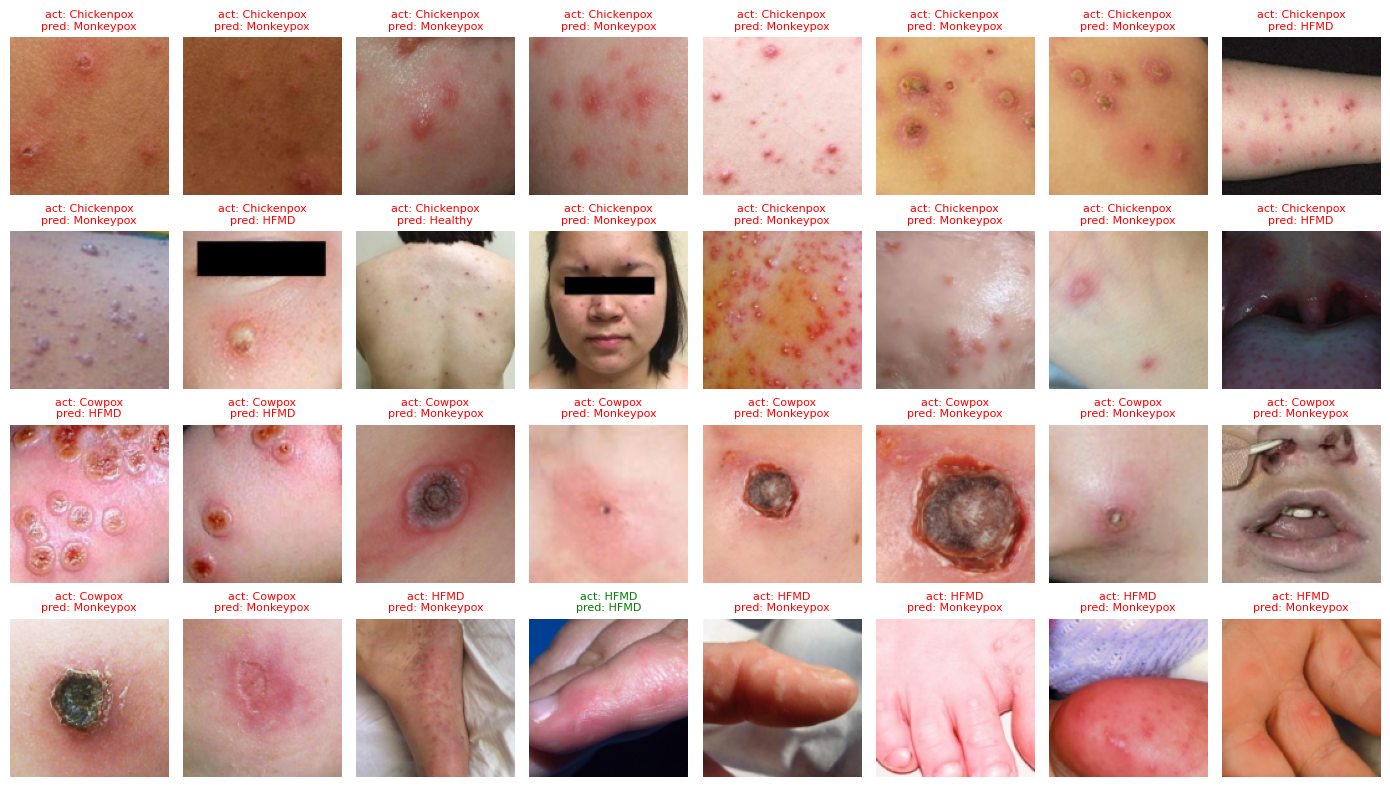

In [43]:
fig, axes = plt.subplots(ncols=8, nrows=4, figsize=(14, 8))
index = 0

for i in range(4):
    for j in range(8):
        ax = axes[i, j]

        # Ambil label asli & prediksi
        act_label = labels_map[y_samples[index].item()]
        pred_label = labels_map[y_samples_pred[index].item()]

        # Warna judul
        color = 'g' if act_label == pred_label else 'r'

        # Convert tensor ke numpy dan transpose (C,H,W -> H,W,C)
        img = X_samples[index].permute(1, 2, 0).numpy()
        img = img.clip(0, 1)

        ax.imshow(img)
        ax.set_title(f'act: {act_label}\npred: {pred_label}',
                     color=color, fontsize=8)
        ax.axis('off')

        index += 1

plt.tight_layout()
plt.show()

## **CONVOLUTIONAL NEURAL NETWORK**
---

In [44]:
class CNNModel(nn.Module):
    def __init__(self):
        super().__init__()

        FINAL_CHANNELS = 256
        NUM_CLASSES = 6

        self.features = nn.Sequential(
            # Conv Block 1
            nn.Conv2d(3, 8, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(8),
            nn.MaxPool2d(2),
            nn.Dropout(0.3),

            # Conv Block 2
            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Conv Block 3
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Conv Block 4
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Conv Block 5
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Conv Block 6 (Output Channel: 256)
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),

            # Lapisan Dense (Linear) pertama setelah GAP
            nn.Linear(FINAL_CHANNELS, 512),
            nn.ReLU(),
            nn.Dropout(0.4),

            # Lapisan Output
            nn.Linear(512, NUM_CLASSES)
        )

    def forward(self, x):

        # Ekstraksi Fitur
        x = self.features(x)

        # Global Average Pooling
        x = self.global_pool(x)

        # Klasifikasi
        x = self.classifier(x)

        return x

model_cnn = CNNModel()
print('Total parameters CNN:', sum(p.nelement() for p in model_cnn.parameters()))

Total parameters CNN: 1314390


In [45]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [46]:
model_cnn = CNNModel().to(device)

In [47]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model_cnn.parameters(), lr=1e-4, weight_decay=1e-4)

In [48]:
losses_cnn, train_acc_cnn, valid_acc_cnn = train(
    model=model_cnn,
    max_epoch=CONFIG.max_epochs,
    train_loader=train_loader,
    optimizer=optimizer
)

Epoch: 001/050 | Batch: 0000/0009 | Loss: 1.7946
Epoch: 001/050 | Batch: 0004/0009 | Loss: 1.7880
Epoch: 001/050 | Batch: 0008/0009 | Loss: 1.7856
Epoch: 001/050 | Train: 37.62% | Valid: 38.19%
Epoch: 002/050 | Batch: 0000/0009 | Loss: 1.7811
Epoch: 002/050 | Batch: 0004/0009 | Loss: 1.7740
Epoch: 002/050 | Batch: 0008/0009 | Loss: 1.7628
Epoch: 002/050 | Train: 37.62% | Valid: 38.19%
Epoch: 003/050 | Batch: 0000/0009 | Loss: 1.7343
Epoch: 003/050 | Batch: 0004/0009 | Loss: 1.7317
Epoch: 003/050 | Batch: 0008/0009 | Loss: 1.8867
Epoch: 003/050 | Train: 37.62% | Valid: 38.19%
Epoch: 004/050 | Batch: 0000/0009 | Loss: 1.6003
Epoch: 004/050 | Batch: 0004/0009 | Loss: 1.5769
Epoch: 004/050 | Batch: 0008/0009 | Loss: 1.6664
Epoch: 004/050 | Train: 37.62% | Valid: 38.19%
Epoch: 005/050 | Batch: 0000/0009 | Loss: 1.5613
Epoch: 005/050 | Batch: 0004/0009 | Loss: 1.5250
Epoch: 005/050 | Batch: 0008/0009 | Loss: 1.4832
Epoch: 005/050 | Train: 37.62% | Valid: 38.19%
Epoch: 006/050 | Batch: 0000/0

In [49]:
train_acc, train_loss = get_inference(model_cnn, 'train')
valid_acc, valid_loss = get_inference(model_cnn, 'valid')
test_acc, test_loss = get_inference(model_cnn, 'test')

summary_df.loc['CNN'] = np.array([
    train_acc.item(),
    valid_acc.item(),
    test_acc.item(),
    train_loss.item(),
    valid_loss.item(),
    test_loss.item()
])

summary_df

,Train Acc,Valid Acc,Test Acc,Train Loss,Valid Loss,Test Loss
MLP,50.651768,34.722221,39.189190,1.364470,1.633735,1.619581
CNN,54.003723,45.138889,45.945946,1.231856,1.590884,1.354863


In [50]:
# Ambil batch valid
X_samples, y_samples = next(iter(valid_loader))

# Prediksi menggunakan CNN
model_cnn.eval()

with torch.no_grad():
    X_samples = X_samples.to(device)

    logits_sample = model_cnn(X_samples)
    probs_sample = F.softmax(logits_sample, dim=1)
    y_samples_pred = probs_sample.argmax(dim=1)

y_samples_pred = y_samples_pred.cpu()
y_samples_pred

tensor([5, 5, 5, 5, 5, 5, 5, 2, 5, 3, 5, 2, 5, 5, 5, 5, 2, 5, 5, 5, 3, 5, 5, 5,
        1, 5, 5, 2, 5, 5, 5, 2, 2, 2, 5, 2, 5, 5, 5, 3, 2, 2, 3, 3, 5, 2, 2, 3,
        2, 2, 5, 5, 2, 5, 2, 5, 3, 3, 3, 2, 3, 3, 2, 5])

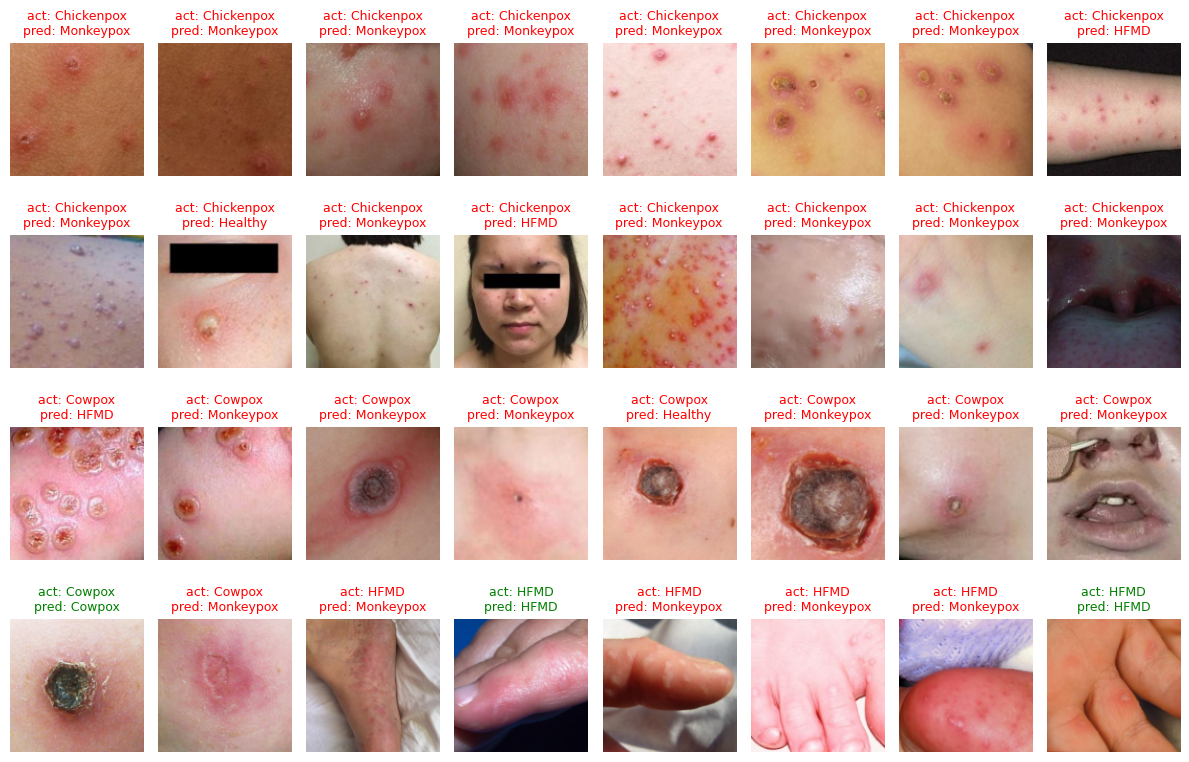

In [51]:

# labels_map otomatis dari folder
labels_map = {i: class_names[i] for i in range(len(class_names))}

fig, axes = plt.subplots(ncols=8, nrows=4, figsize=(12, 8))
index = 0

for i in range(4):
    for j in range(8):

        act_label = labels_map[y_samples[index].item()]
        pred_label = labels_map[y_samples_pred[index].item()]

        color = 'g' if act_label == pred_label else 'r'

        axes[i,j].set_title(
            f'act: {act_label}\npred: {pred_label}',
            color=color, size=9
        )

        img = X_samples[index].cpu().permute(1, 2, 0).numpy()

        axes[i,j].imshow(img)
        axes[i,j].axis('off')

        index += 1

plt.tight_layout()
plt.show()


In [52]:
print(len(losses_cnn))
print(len(train_acc_cnn))
print(len(valid_acc_cnn))

450
50
50


In [53]:
# Karena tiap epoch ada 9 batch
losses_per_epoch = np.array(losses_cnn).reshape(-1, 9).mean(axis=1)

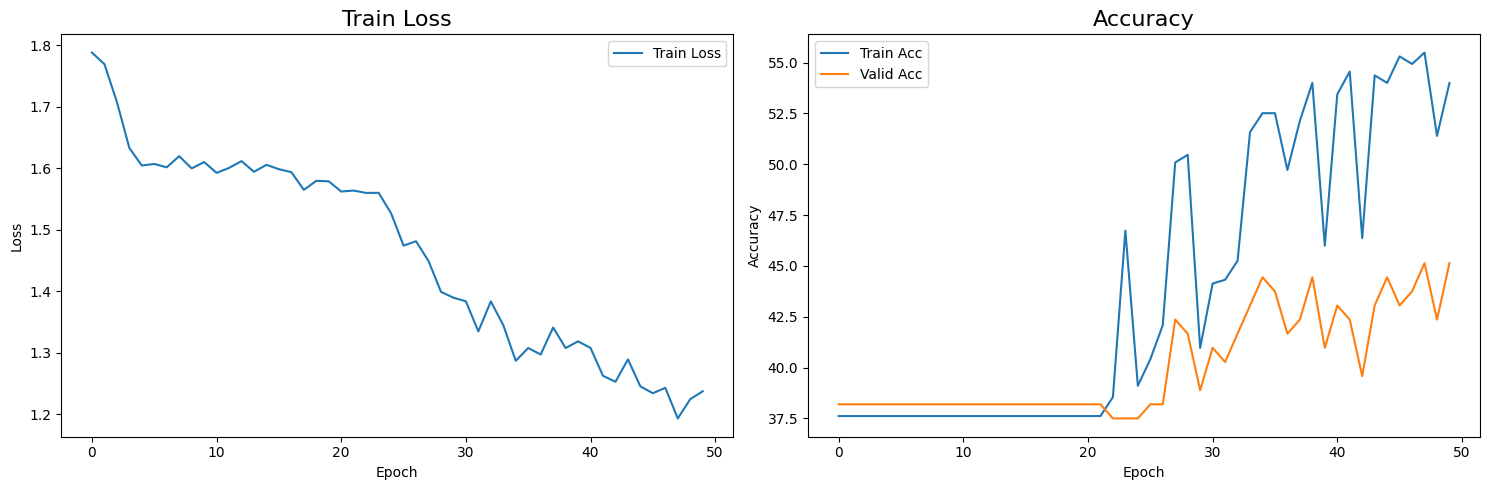

In [54]:
hist_cnn = pd.DataFrame({
    "loss": losses_per_epoch,
    "train_acc": train_acc_cnn,
    "valid_acc": valid_acc_cnn
})

plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(hist_cnn['loss'], label='Train Loss')
plt.title('Train Loss', fontsize=16)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist_cnn['train_acc'], label='Train Acc')
plt.plot(hist_cnn['valid_acc'], label='Valid Acc')
plt.title('Accuracy', fontsize=16)
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [55]:
def get_full_predictions(model, data_loader, device):

    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs = inputs.to(device)

            outputs = model(inputs)

            _, preds = torch.max(outputs, 1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    return np.array(y_true), np.array(y_pred)

y_true_test, y_pred_test = get_full_predictions(model_cnn, test_loader, device)

print("\n========================================================")
print("              CLASSIFICATION REPORT      ")
print("========================================================")
print(classification_report(y_true_test, y_pred_test, target_names=class_names))


              CLASSIFICATION REPORT      
              precision    recall  f1-score   support

  Chickenpox       0.00      0.00      0.00         9
      Cowpox       1.00      0.14      0.25         7
        HFMD       0.43      0.38      0.40        16
     Healthy       0.33      0.44      0.38         9
     Measles       0.00      0.00      0.00         6
   Monkeypox       0.49      0.85      0.62        27

    accuracy                           0.46        74
   macro avg       0.38      0.30      0.28        74
weighted avg       0.41      0.46      0.38        74



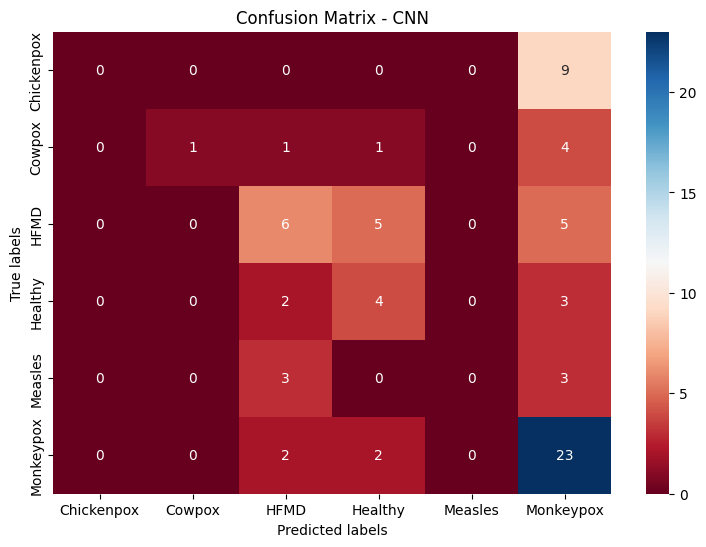

In [56]:
CM = confusion_matrix(y_true_test, y_pred_test)

plt.figure(figsize=(9, 6))
sns.heatmap(
    CM,
    annot=True,
    fmt='g',
    cmap='RdBu',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix - CNN')
plt.show()

In [57]:
def predict_image(model, image_path, class_names, device):
    model.eval()

    # Load image
    img = cv2.imread(image_path)

    if img is None:
        raise FileNotFoundError(
            f"Image not found or cannot be read: {image_path}"
        )

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Resize to match training dimensions (128x128)
    img_resized = cv2.resize(img, (128, 128))

    # Convert to tensor (C, H, W)
    img_tensor = torch.tensor(
        img_resized, dtype=torch.float32
    ).permute(2, 0, 1) / 255.0

    img_tensor = img_tensor.unsqueeze(0).to(device)

    # Predict
    with torch.no_grad():
        logits = model(img_tensor)
        probs = F.softmax(logits, dim=1)
        pred_class = probs.argmax(dim=1).item()
        confidence = probs[0, pred_class].item()

    predicted_label = class_names[pred_class]

    # Display
    plt.figure(figsize=(5, 5))
    plt.imshow(img_resized)
    plt.title(
        f"Prediction: {predicted_label}\n"
        f"Confidence: {confidence:.2%}"
    )
    plt.axis('off')
    plt.show()

    return predicted_label


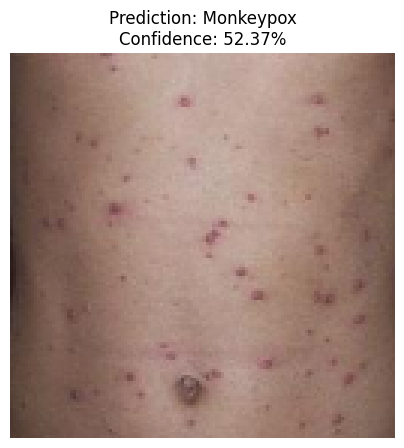

'Monkeypox'

In [58]:
image_path = list(
    Path(path).rglob("CHP_01_01.jpg")
)[0]

predict_image(
    model=model_cnn,
    image_path=str(image_path),
    class_names=class_names,
    device=device
)

## **RESIDUAL NETWORK (RESNET)-18**
---
ResNet diperkenalkan oleh Microsoft Research (He et al., 2015) dan terkenal karena konsep skip connection / residual connection, yang membantu mengatasi masalah vanishing gradient pada jaringan deep learning yang sangat dalam.

In [59]:
# Memuat arsitektur Pre-trained ResNet-18 dan bobot yang dilatih di ImageNet
model_resnet18 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

# Ganti Lapisan Fully Connected (Classifier)
num_ftrs = model_resnet18.fc.in_features
model_resnet18.fc = nn.Sequential(
    nn.Dropout(CONFIG.drop_proba),
    nn.Linear(num_ftrs, CONFIG.n_out)
)

# Pindahkan model ke device
model_resnet = model_resnet18.to(device)
print(f"Total parameters ResNet-18 Pre-trained: {sum(p.nelement() for p in model_resnet.parameters())}")

Total parameters ResNet-18 Pre-trained: 11179590


In [60]:
# Data Distribusi
class_counts = {
    'Chickenpox': 50, 'Cowpox': 49, 'HFMD': 116,
    'Healthy': 83, 'Measles': 37, 'Monkeypox': 202
}
total_samples = sum(class_counts.values())
class_names_ordered = ['Chickenpox', 'Cowpox', 'HFMD', 'Healthy', 'Measles', 'Monkeypox']

counts = np.array([class_counts[name] for name in class_names_ordered])
weights = total_samples / counts
weights_normalized = weights / np.sum(weights)

class_weights = torch.tensor(weights_normalized, dtype=torch.float32).to(device)

# Criterion Weighted
criterion_weighted = nn.CrossEntropyLoss(weight=class_weights)

# OPTIMIZER
optimizer_resnet = torch.optim.Adam(
    model_resnet18.parameters(),
    lr=CONFIG.lr,
    weight_decay=1e-4
)

Epoch: 001/050 | Batch: 0000/0009 | Loss: 2.0858
Epoch: 001/050 | Batch: 0004/0009 | Loss: 1.7107
Epoch: 001/050 | Batch: 0008/0009 | Loss: 1.3529
Epoch: 001/050 | Train: 57.91% | Valid: 44.44%
Epoch: 002/050 | Batch: 0000/0009 | Loss: 0.8929
Epoch: 002/050 | Batch: 0004/0009 | Loss: 0.6800
Epoch: 002/050 | Batch: 0008/0009 | Loss: 0.4339
Epoch: 002/050 | Train: 75.42% | Valid: 52.78%
Epoch: 003/050 | Batch: 0000/0009 | Loss: 0.4163
Epoch: 003/050 | Batch: 0004/0009 | Loss: 0.3046
Epoch: 003/050 | Batch: 0008/0009 | Loss: 0.2296
Epoch: 003/050 | Train: 88.83% | Valid: 62.50%
Epoch: 004/050 | Batch: 0000/0009 | Loss: 0.2690
Epoch: 004/050 | Batch: 0004/0009 | Loss: 0.2266
Epoch: 004/050 | Batch: 0008/0009 | Loss: 0.2186
Epoch: 004/050 | Train: 97.02% | Valid: 65.97%
Epoch: 005/050 | Batch: 0000/0009 | Loss: 0.1265
Epoch: 005/050 | Batch: 0004/0009 | Loss: 0.1012
Epoch: 005/050 | Batch: 0008/0009 | Loss: 0.0773
Epoch: 005/050 | Train: 99.63% | Valid: 70.14%
Epoch: 006/050 | Batch: 0000/0

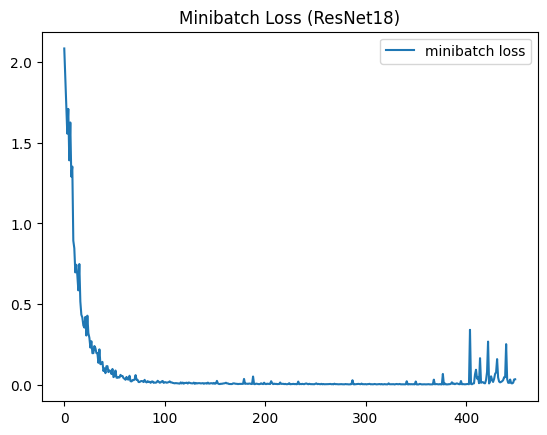

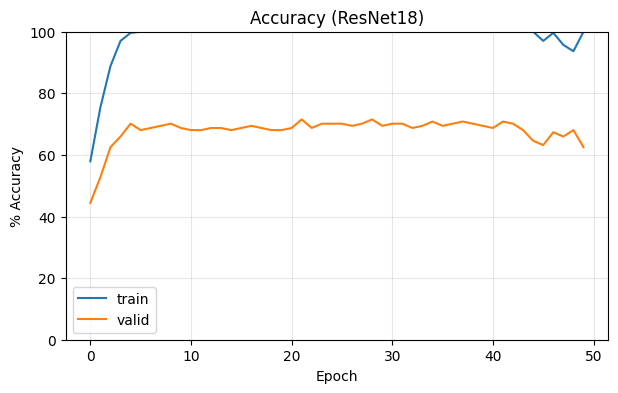

In [61]:
# Lakukan Training ResNet dengan Weighted Criterion
losses_resnet, train_acc_resnet, valid_acc_resnet = train(
    model=model_resnet18,
    max_epoch=CONFIG.max_epochs,
    train_loader=train_loader,
    optimizer=optimizer_resnet,
    criterion=criterion_weighted
)

# Plot Loss
plt.plot(np.arange(len(losses_resnet)), losses_resnet, c='tab:blue', label='minibatch loss')
plt.legend()
plt.title('Minibatch Loss (ResNet18)')
plt.show()

# Plot Accuracy
plt.figure(figsize=(7,4))
plt.plot(np.arange(len(train_acc_resnet)), train_acc_resnet, c='tab:blue', label='train')
plt.plot(np.arange(len(valid_acc_resnet)), valid_acc_resnet, c='tab:orange', label='valid')
plt.ylabel('% Accuracy')
plt.xlabel('Epoch')
plt.ylim(0, 100)
plt.legend()
plt.grid(alpha=0.3)
plt.title('Accuracy (ResNet18)')
plt.show()

In [62]:
# Hitung metrik akhir
train_acc, train_loss = get_inference(model_resnet18, 'train')
valid_acc, valid_loss = get_inference(model_resnet18, 'valid')
test_acc, test_loss = get_inference(model_resnet18, 'test')

# Tambahkan metrik ke DataFrame dengan indeks baru
summary_df.loc['ResNet18'] = np.array([
    train_acc.item(),
    valid_acc.item(),
    test_acc.item(),
    train_loss.item(),
    valid_loss.item(),
    test_loss.item()
])

summary_df

,Train Acc,Valid Acc,Test Acc,Train Loss,Valid Loss,Test Loss
MLP,50.651768,34.722221,39.189190,1.364470,1.633735,1.619581
CNN,54.003723,45.138889,45.945946,1.231856,1.590884,1.354863
ResNet18,100.000000,62.500000,67.567566,0.014473,1.233387,1.014359


In [63]:
# Ambil batch valid
X_samples, y_samples = next(iter(valid_loader))

# Prediksi menggunakan ResNet18
model_resnet18.eval()

with torch.no_grad():
    X_samples = X_samples.to(device)

    logits_sample = model_resnet18(X_samples)
    probs_sample = F.softmax(logits_sample, dim=1)
    y_samples_pred = probs_sample.argmax(dim=1)

y_samples_pred = y_samples_pred.cpu()
y_samples_pred

tensor([5, 5, 0, 0, 0, 0, 0, 2, 5, 0, 2, 3, 0, 0, 5, 5, 4, 5, 1, 1, 1, 1, 5, 2,
        1, 5, 5, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 4, 3, 3, 3, 3, 5, 2, 3, 5, 3])

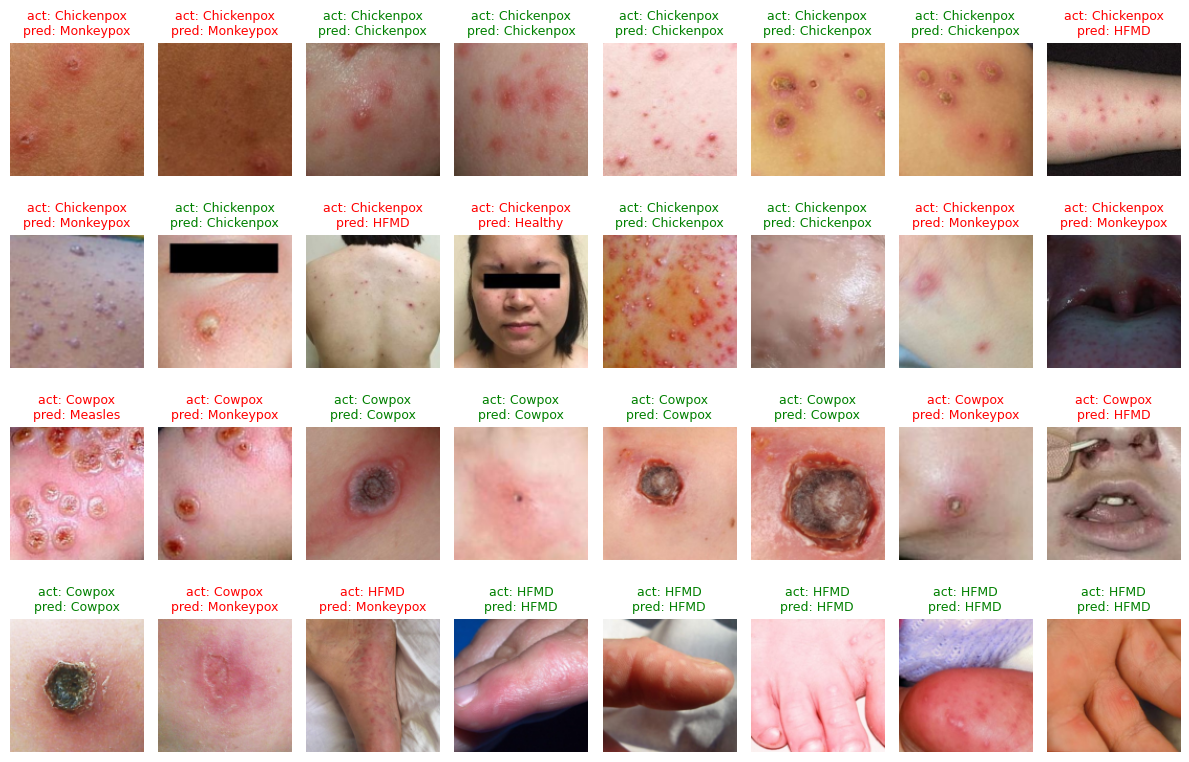

In [64]:

# labels_map otomatis dari folder
labels_map = {i: class_names[i] for i in range(len(class_names))}

fig, axes = plt.subplots(ncols=8, nrows=4, figsize=(12, 8))
index = 0

for i in range(4):
    for j in range(8):

        act_label = labels_map[y_samples[index].item()]
        pred_label = labels_map[y_samples_pred[index].item()]

        color = 'g' if act_label == pred_label else 'r'

        axes[i,j].set_title(
            f'act: {act_label}\npred: {pred_label}',
            color=color, size=9
        )

        img = X_samples[index].cpu().permute(1, 2, 0).numpy()

        axes[i,j].imshow(img)
        axes[i,j].axis('off')

        index += 1

plt.tight_layout()
plt.show()

In [65]:
def get_full_predictions(model, data_loader, device):

    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs = inputs.to(device)

            outputs = model(inputs)

            _, preds = torch.max(outputs, 1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    return np.array(y_true), np.array(y_pred)

y_true_test, y_pred_test = get_full_predictions(model_resnet18, test_loader, device)

print("\n========================================================")
print("              CLASSIFICATION REPORT      ")
print("========================================================")
print(classification_report(y_true_test, y_pred_test, target_names=class_names))


              CLASSIFICATION REPORT      
              precision    recall  f1-score   support

  Chickenpox       0.60      0.33      0.43         9
      Cowpox       0.67      0.29      0.40         7
        HFMD       0.70      0.88      0.78        16
     Healthy       0.62      0.89      0.73         9
     Measles       0.75      0.50      0.60         6
   Monkeypox       0.69      0.74      0.71        27

    accuracy                           0.68        74
   macro avg       0.67      0.60      0.61        74
weighted avg       0.67      0.68      0.66        74



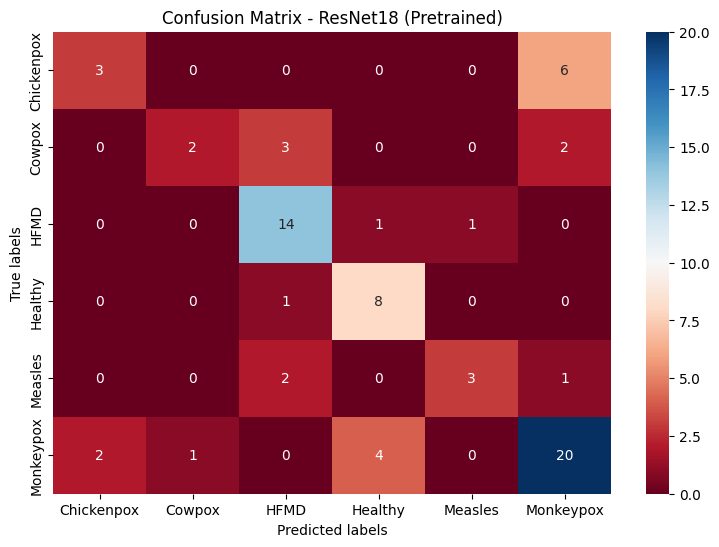

In [66]:
CM = confusion_matrix(y_true_test, y_pred_test)

plt.figure(figsize=(9, 6))
sns.heatmap(
    CM,
    annot=True,
    fmt='g',
    cmap='RdBu',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix - ResNet18 (Pretrained)')
plt.show()